# Paracetamol: torsion distributions written in one labelling

The symmetry-first clustering ([previous notebook](clustering.ipynb)) found two clusters. This page
asks a different question of the same fit: **how should a torsion histogram be drawn when the same
configuration can be written in more than one atom labelling?** The ring flip renames C5 as C10, so
a frame can appear as `aryl = -16` degrees or as `aryl = 164` degrees, and a histogram of the stored
column shows both. Each frame is written in the labelling **nearest one reference frame**, the
density peak of the largest cluster, and every operation acts on the whole row of angles at once.

The explanation, the definitions and the limits are in
[Methods: analysis, symmetry-aware clustering and the torsion representation](../../../openmm_methods/analysis/clustering-and-symmetry.md);
this page shows what the rule gives on paracetamol and nothing else.

!!! note "Relabelling moves no atom and drops no frame"
    Every frame is kept, once. The operation used is returned per frame.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1] / "_analysis"))   # docs/tutorial/_analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj as md
from rdkit import Chem
import tutorial_data as td
import md_tools
from md_tools.analysis import (TorsionDefinitions, t_hdbscan, verify_atom_mapping, group_name)

print("tutorial runs:", "found" if td.runs_root().is_dir() else "MISSING")
print("md-tools", md_tools.__version__, "+ the unreleased THDBSCAN.density_peak / align_all and "
      "SymmetricTorsionDescriptor.align_to_reference")

tutorial runs: found
md-tools 0.6.5 + the unreleased THDBSCAN.density_peak / align_all and SymmetricTorsionDescriptor.align_to_reference


## 1. The fit this page starts from

The same input as the clustering notebook: the 1 us cMD run at stride 25 (4000 frames), the three
selected torsions, and the default `t_hdbscan` call with the symmetry-aware distance, a mass floor of
1 % of the fitted frames (`min_cluster_size` 40) and `min_samples` 40.

In [2]:
mol = Chem.SDMolSupplier(str(td.run_dir("PARA-REST2") / "build/TYL.sdf"), removeHs=False)[0]
TORSIONS = {"omega": (0, 1, 3, 4), "aryl": (1, 3, 4, 5), "phenol": (6, 7, 8, 17)}
definitions = TorsionDefinitions(quads=tuple(TORSIONS.values()), names=tuple(TORSIONS),
                                 indexing="zero-based", units="radian")
cmd = td.solute("PARA-1us", stride=25)
tors = md.compute_dihedrals(cmd, list(TORSIONS.values()))
mapping, why = verify_atom_mapping(mol, [(b[0].index, b[1].index) for b in cmd.topology.bonds],
                                   [a.element.symbol for a in cmd.topology.atoms])
fit = t_hdbscan(tors, molecule=mol, torsion_definitions=definitions, coordinates=cmd,
                atom_mapping=mapping).fit()
desc = fit.descriptor_
s = fit.summary()
print(f"{s['n_fit_frames']} frames, {s['n_clusters']} clusters, min_cluster_size "
      f"{s['settings']['min_cluster_size']}, min_samples {s['settings']['min_samples']}")
pd.DataFrame([{"cluster": group_name(c), "frames": int((fit.labels_ == c).sum()),
               "mass": round(float(fit.cluster_mass_[c]), 4)} for c in range(fit.n_clusters_)]
             + [{"cluster": "density noise", "frames": int((fit.labels_ == -2).sum()),
                 "mass": round(float(fit.noise_mass_), 4)}])

4000 frames, 2 clusters, min_cluster_size 40, min_samples 40


,cluster,frames,mass
0,A,2056,0.5140
1,B,1935,0.4838
2,density noise,9,0.0022


## 2. The columns and their weights

A torsion's image under the ring flip is a column of its own, computed from coordinates. Each orbit
carries the weight of the torsions selected in it, split equally among its columns, so the ring
orientation counts once.

In [3]:
pd.DataFrame([{"column": n, "atoms": "-".join(map(str, q)), "weight": w,
               "origin": "selected" if o["kind"] == "selected" else f"image of {o['image_of']}"}
              for n, q, w, o in zip(desc.names, desc.quads, desc.column_weights, desc.origin)])

,column,atoms,weight,origin
0,omega,0-1-3-4,1.0,selected
1,aryl,1-3-4-5,0.5,selected
2,phenol,6-7-8-17,0.5,selected
3,aryl@1-3-4-10,1-3-4-10,0.5,image of aryl
4,phenol@9-7-8-17,9-7-8-17,0.5,image of phenol


## 3. The reference: the density peak of the largest cluster

The reference is an actual frame, the member of cluster A with the smallest core distance (the
distance to its 40th nearest fitted frame under the symmetry-aware distance).

In [4]:
ref = fit.density_peak(0)
print(f"reference: frame {ref}, cluster {group_name(int(fit.labels_[ref]))}, "
      f"core distance {fit.core_distance_[ref]:.3f}")
pd.DataFrame(np.rad2deg(fit.closed_theta_[[ref]]), columns=desc.names, index=["reference"]).round(1)

reference: frame 3899, cluster A, core distance 0.153


,omega,aryl,phenol,aryl@1-3-4-10,phenol@9-7-8-17
reference,173.4,-16.0,8.0,167.0,-171.7


## 4. Every frame in the labelling nearest the reference

Each cluster's frames are aligned to the cluster's own density peak, and that peak is written in the
labelling nearest the reference above. The `margin` is the distance of a frame's second-best
labelling minus its best; a small margin means the frame sits near the wall between two labellings
and the choice is arbitrary.

In [5]:
al = fit.align_all(per_cluster=True)
rows = []
for c in range(fit.n_clusters_):
    m = fit.labels_ == c
    rows.append({"cluster": group_name(c), "density peak": int(al["cluster_references"][c]),
                 "frames relabelled": round(float((al["operations"][m] != 0).mean()), 3),
                 "mean distance, no relabelling": round(float(al["distance_identity"][m].mean()), 3),
                 "mean distance, nearest": round(float(al["distance"][m].mean()), 3),
                 "frames with margin < 0.1": round(float((al["margin"][m] < 0.1).mean()), 3)})
pd.DataFrame(rows)

,cluster,density peak,frames relabelled,"mean distance, no relabelling","mean distance, nearest",frames with margin < 0.1
0,A,3899,0.547,1.795,0.623,0.0
1,B,3271,0.434,1.584,0.689,0.0


## 5. The marginals, as stored and written in one labelling

Top: as stored. Bottom: every frame in the labelling nearest the reference. The five columns are the
three selected torsions and the two ring-flip images that were added to close the descriptor.

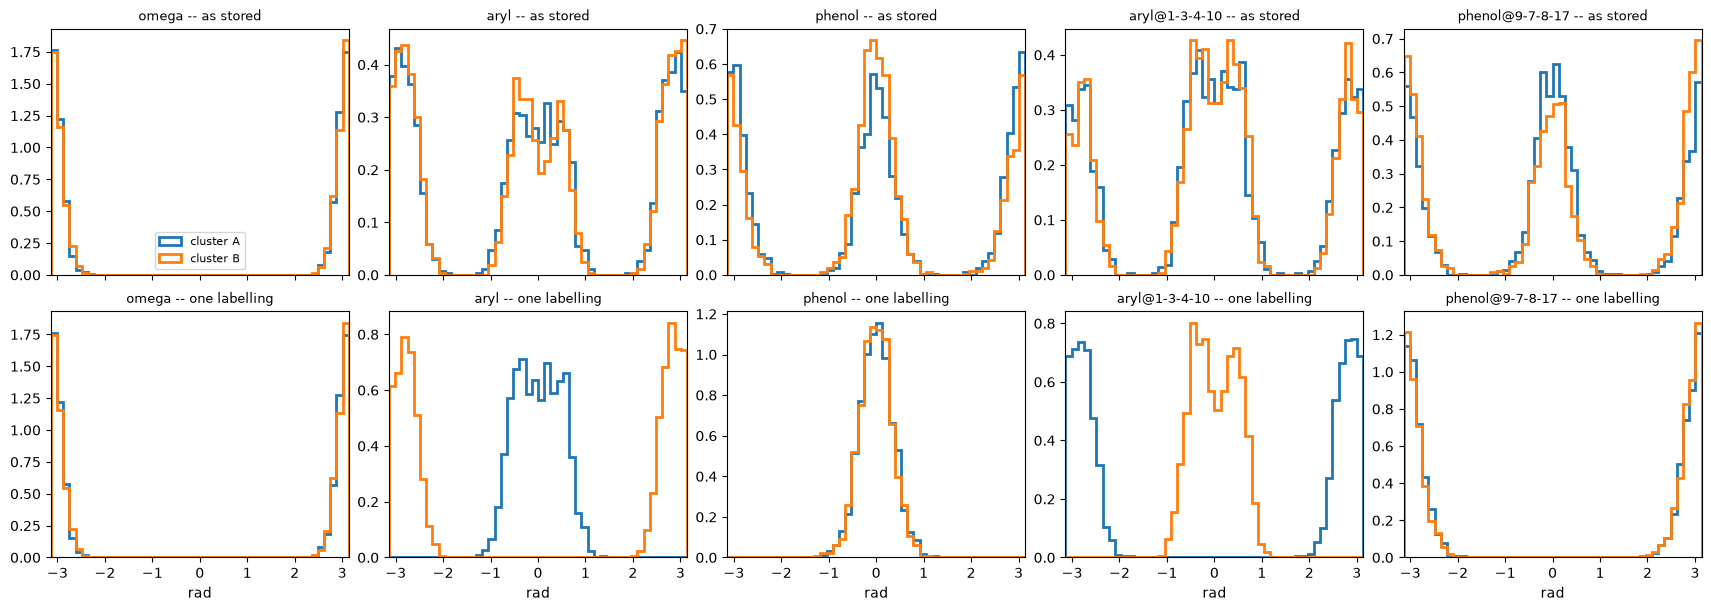

In [6]:
edges = np.linspace(-np.pi, np.pi, 49)
palette = plt.get_cmap("tab10")
fig, axes = plt.subplots(2, 5, figsize=(17, 6), layout="constrained", sharex=True)
for r, (title, theta) in enumerate((("as stored", fit.closed_theta_), ("one labelling", al["angles"]))):
    for col, name in enumerate(desc.names):
        for k in range(fit.n_clusters_):
            axes[r, col].hist(theta[fit.labels_ == k, col], bins=edges, density=True, histtype="step",
                              lw=2.0, color=palette(k), label=f"cluster {group_name(k)}")
        axes[r, col].set_xlim(-np.pi, np.pi)
        axes[r, col].set_title(f"{name} -- {title}", fontsize=9)
for col in range(5):
    axes[1, col].set_xlabel("rad")
axes[0, 0].legend(fontsize=8)
plt.show()

## 6. The ring pair

`aryl` (1-3-4-5) and its image `aryl@1-3-4-10` are one rotation seen through two atoms: the second is
the first plus half a turn plus a small ring distortion `delta`. The flip swaps the two columns, so it
maps `delta` to `-delta`.

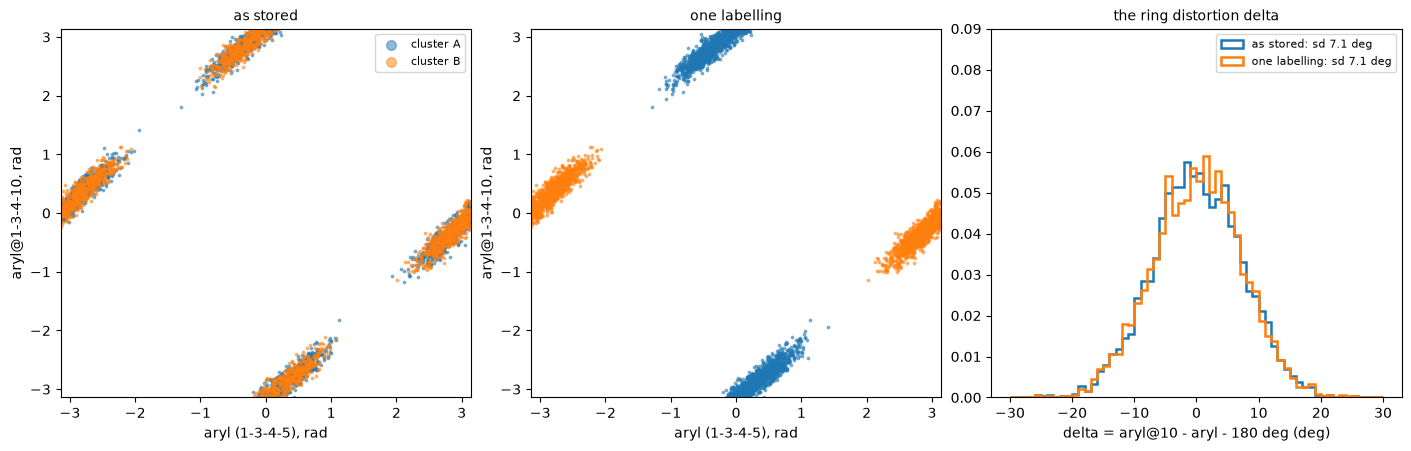

In [7]:
a, b = desc.names.index("aryl"), desc.names.index("aryl@1-3-4-10")
wrap = lambda x: np.angle(np.exp(1j * x))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), layout="constrained")
panels = [("as stored", fit.closed_theta_), ("one labelling", al["angles"])]
for ax, (title, th) in zip(axes[:2], panels):
    for k in range(fit.n_clusters_):
        sel = fit.labels_ == k
        ax.scatter(th[sel, a], th[sel, b], s=3, alpha=0.5, color=palette(k), label=f"cluster {group_name(k)}")
    ax.set_xlim(-np.pi, np.pi); ax.set_ylim(-np.pi, np.pi)
    ax.set_xlabel("aryl (1-3-4-5), rad"); ax.set_ylabel("aryl@1-3-4-10, rad"); ax.set_title(title, fontsize=10)
axes[0].legend(markerscale=4, fontsize=8)
bins = np.linspace(-30, 30, 61)
for title, th in panels:
    delta = np.rad2deg(wrap(th[:, b] - th[:, a] - np.pi))
    axes[2].hist(delta, bins=bins, density=True, histtype="step", lw=1.8,
                 label=f"{title}: sd {delta.std():.1f} deg")
axes[2].set_xlabel("delta = aryl@10 - aryl - 180 deg (deg)"); axes[2].set_ylim(0, 0.09)
axes[2].legend(fontsize=8); axes[2].set_title("the ring distortion delta", fontsize=10)
plt.show()

The partner is not a second free torsion: it stays on the line `aryl + 180 deg`. What is left is
`delta`, the ring distortion, and on this trajectory it is symmetric about zero in every cluster
(mean 0.1 deg, standard deviation 7.1 deg, as stored and relabelled alike), so the relabelling leaves
its histogram where it was.

## 7. Torsion table, in the one labelling

Circular mean and circular standard deviation of each selected torsion, per cluster.

In [8]:
def circ(values):
    R = np.hypot(np.sin(values).mean(), np.cos(values).mean())
    return np.rad2deg(np.arctan2(np.sin(values).mean(), np.cos(values).mean())), np.rad2deg(np.sqrt(-2.0 * np.log(max(R, 1e-12))))

rows = []
for c in range(fit.n_clusters_):
    row = {"cluster": group_name(c)}
    for j, n in enumerate(definitions.names):
        mean, sd = circ(al["selected"][fit.labels_ == c, j])
        row[f"{n}_avg"], row[f"{n}_std"] = round(mean, 2), round(sd, 2)
    row["mass"] = round(float(fit.cluster_mass_[c]), 4)
    rows.append(row)
pd.DataFrame(rows)

,cluster,omega_avg,omega_std,aryl_avg,aryl_std,phenol_avg,phenol_std,mass
0,A,179.87,12.31,0.03,27.76,-0.00,19.88,0.5140
1,B,179.95,12.67,-179.53,24.46,-0.77,19.35,0.4838
